**Lab 3 — Transforming Textual and Image Data into a Machine-Understandable Format**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832

In [1]:
!pip install scikit-learn Pillow numpy pandas matplotlib

In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define Sample Text Data (our "corpus")
documents = [
    "The sun is shining today.",
    "The weather is good, the sun is great.",
    "A sunny day is a wonderful day."
]

print("--- Raw Text Documents ---")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

--- Raw Text Documents ---
Doc 1: The sun is shining today.
Doc 2: The weather is good, the sun is great.
Doc 3: A sunny day is a wonderful day.


In [3]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['day' 'good' 'great' 'is' 'shining' 'sun' 'sunny' 'the' 'today' 'weather'
 'wonderful']
Shape of Feature Matrix: (3, 11)   (documents x unique terms)


In [4]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)

BoW Numerical Feature Matrix (Machine Understandable Format):



,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1


In [5]:
# Prove the two silent decisions to yourself rather than taking them on trust.

print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [6]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 33
Zero cells   : 18
Sparsity     : 54.5%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


In [9]:
from google.colab import files
uploaded = files.upload()
image_file_path = list(uploaded.keys())[0]   # becomes 'me.jpeg'
print("Using:", image_file_path)

Saving me.jpeg to me.jpeg
Using: me.jpeg


In [11]:
import numpy as np
from PIL import Image
import os

image_file_path = 'me.jpeg'

original_image = None
if image_file_path and os.path.exists(image_file_path):
    try:
        original_image = Image.open(image_file_path)
        print(f"--- Loaded Image from File: {image_file_path} ---")
    except Exception as e:
        print(f"Error loading image from {image_file_path}: {e}")
        dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
        original_image = Image.fromarray(dummy, 'RGB')
        print("--- Created Dummy Image (100x100 RGB) ---")
else:
    print("No valid image file path provided or file not found.")
    dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, 'RGB')
    print("--- Created Dummy Image (100x100 RGB) ---")

# Ensure a consistent 3-channel representation
original_image = original_image.convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

--- Loaded Image from File: me.jpeg ---
Original Image Size (H, W, Channels): (1600, 1214, 3)
Total Features (Pixels) in RGB: 5827200


--- Loaded Image from File: me.jpeg ---
Original Image Size (H, W, Channels): (1600, 1214, 3)
Total Features (Pixels) in RGB: 5827200


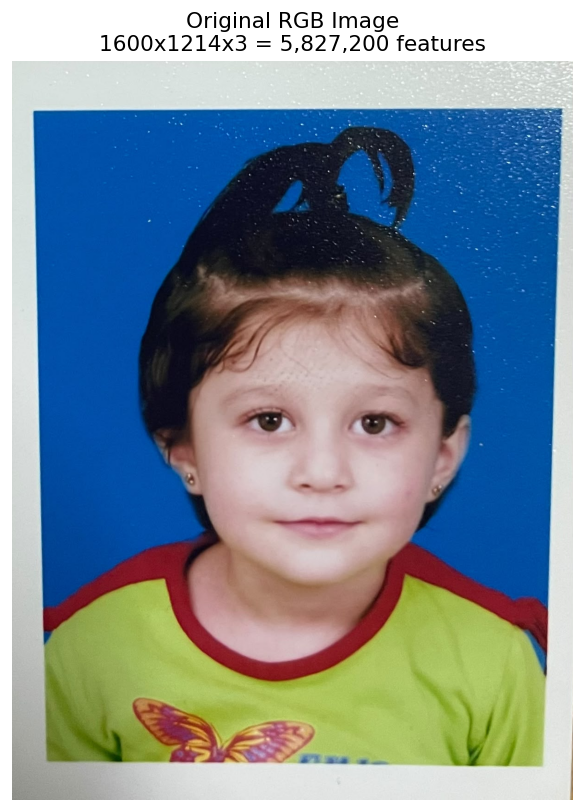

In [13]:
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt

image_file_path = 'me.jpeg'

original_image = None
if image_file_path and os.path.exists(image_file_path):
    try:
        original_image = Image.open(image_file_path)
        print(f"--- Loaded Image from File: {image_file_path} ---")
    except Exception as e:
        print(f"Error loading image from {image_file_path}: {e}")
        dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
        original_image = Image.fromarray(dummy, 'RGB')
        print("--- Created Dummy Image (100x100 RGB) ---")
else:
    print("No valid image file path provided or file not found.")
    dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, 'RGB')
    print("--- Created Dummy Image (100x100 RGB) ---")

original_image = original_image.convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

# --- Display the original image ---
plt.figure(figsize=(8, 8), dpi=120)
plt.imshow(original_image)
plt.title(f"Original RGB Image\n{h}x{w}x{c} = {h*w*c:,} features", fontsize=13)
plt.axis('off')
plt.show()

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (1600, 1214)
Total Features (Pixels) after Grayscale: 1942400

Reduction factor: 3x fewer features


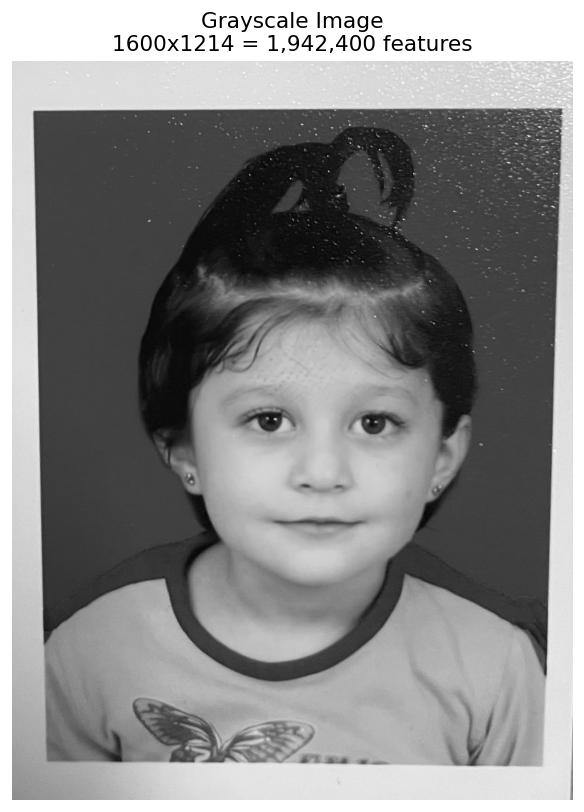

In [14]:
grayscale_image = original_image.convert('L')
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print()
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

# --- Display the grayscale image ---
plt.figure(figsize=(8, 8), dpi=120)
plt.imshow(grayscale_image, cmap='gray')
plt.title(f"Grayscale Image\n{h}x{w} = {h*w:,} features", fontsize=13)
plt.axis('off')
plt.show()

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (1942400,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[219 219 219 219 219 219 219 219 218 218]

Data Type of Final Features: uint8


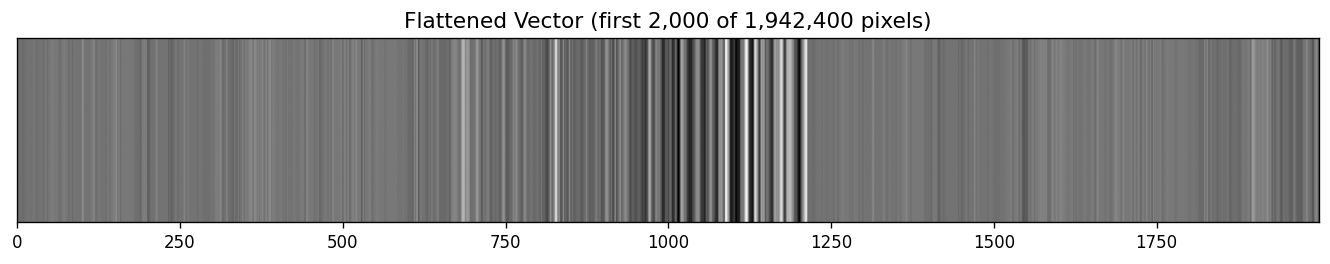

In [15]:
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print()
print("First 10 Features (Pixel Values) in Machine Understandable Format:")
print(flattened_features[:10])
print()
print(f"Data Type of Final Features: {flattened_features.dtype}")

# --- Display the flattened vector as one row of pixels ---
plt.figure(figsize=(14, 2), dpi=120)
plt.imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
plt.title(f"Flattened Vector (first 2,000 of {flattened_features.size:,} pixels)", fontsize=13)
plt.yticks([])
plt.show()

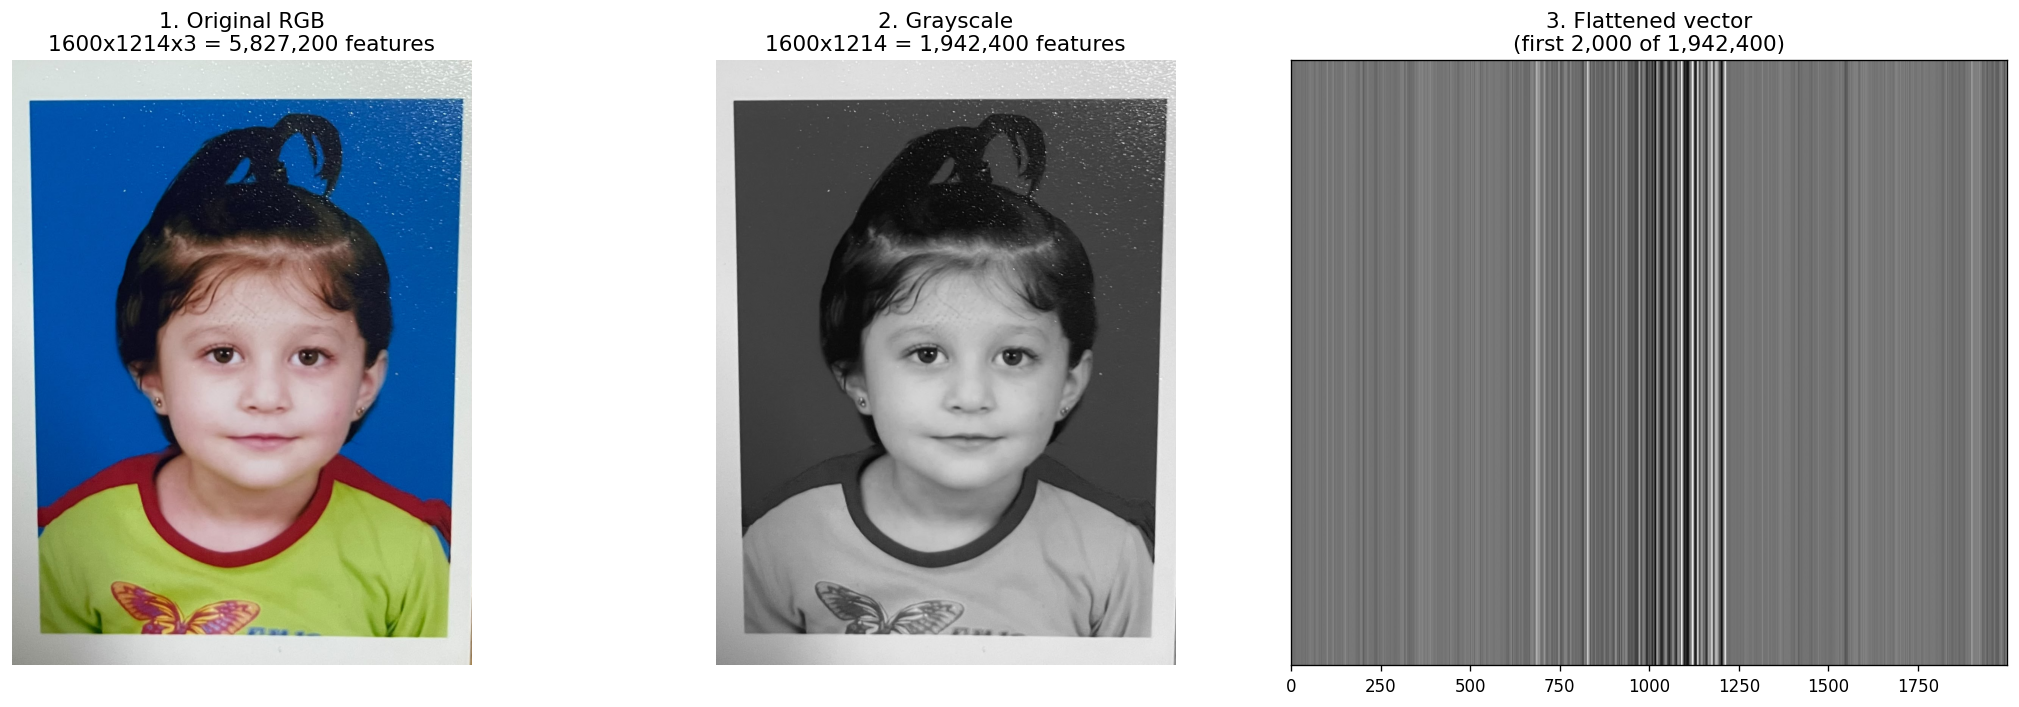

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)

axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features", fontsize=13)
axes[0].axis('off')

axes[1].imshow(grayscale_image, cmap='gray')
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features", fontsize=13)
axes[1].axis('off')

axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})", fontsize=13)
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

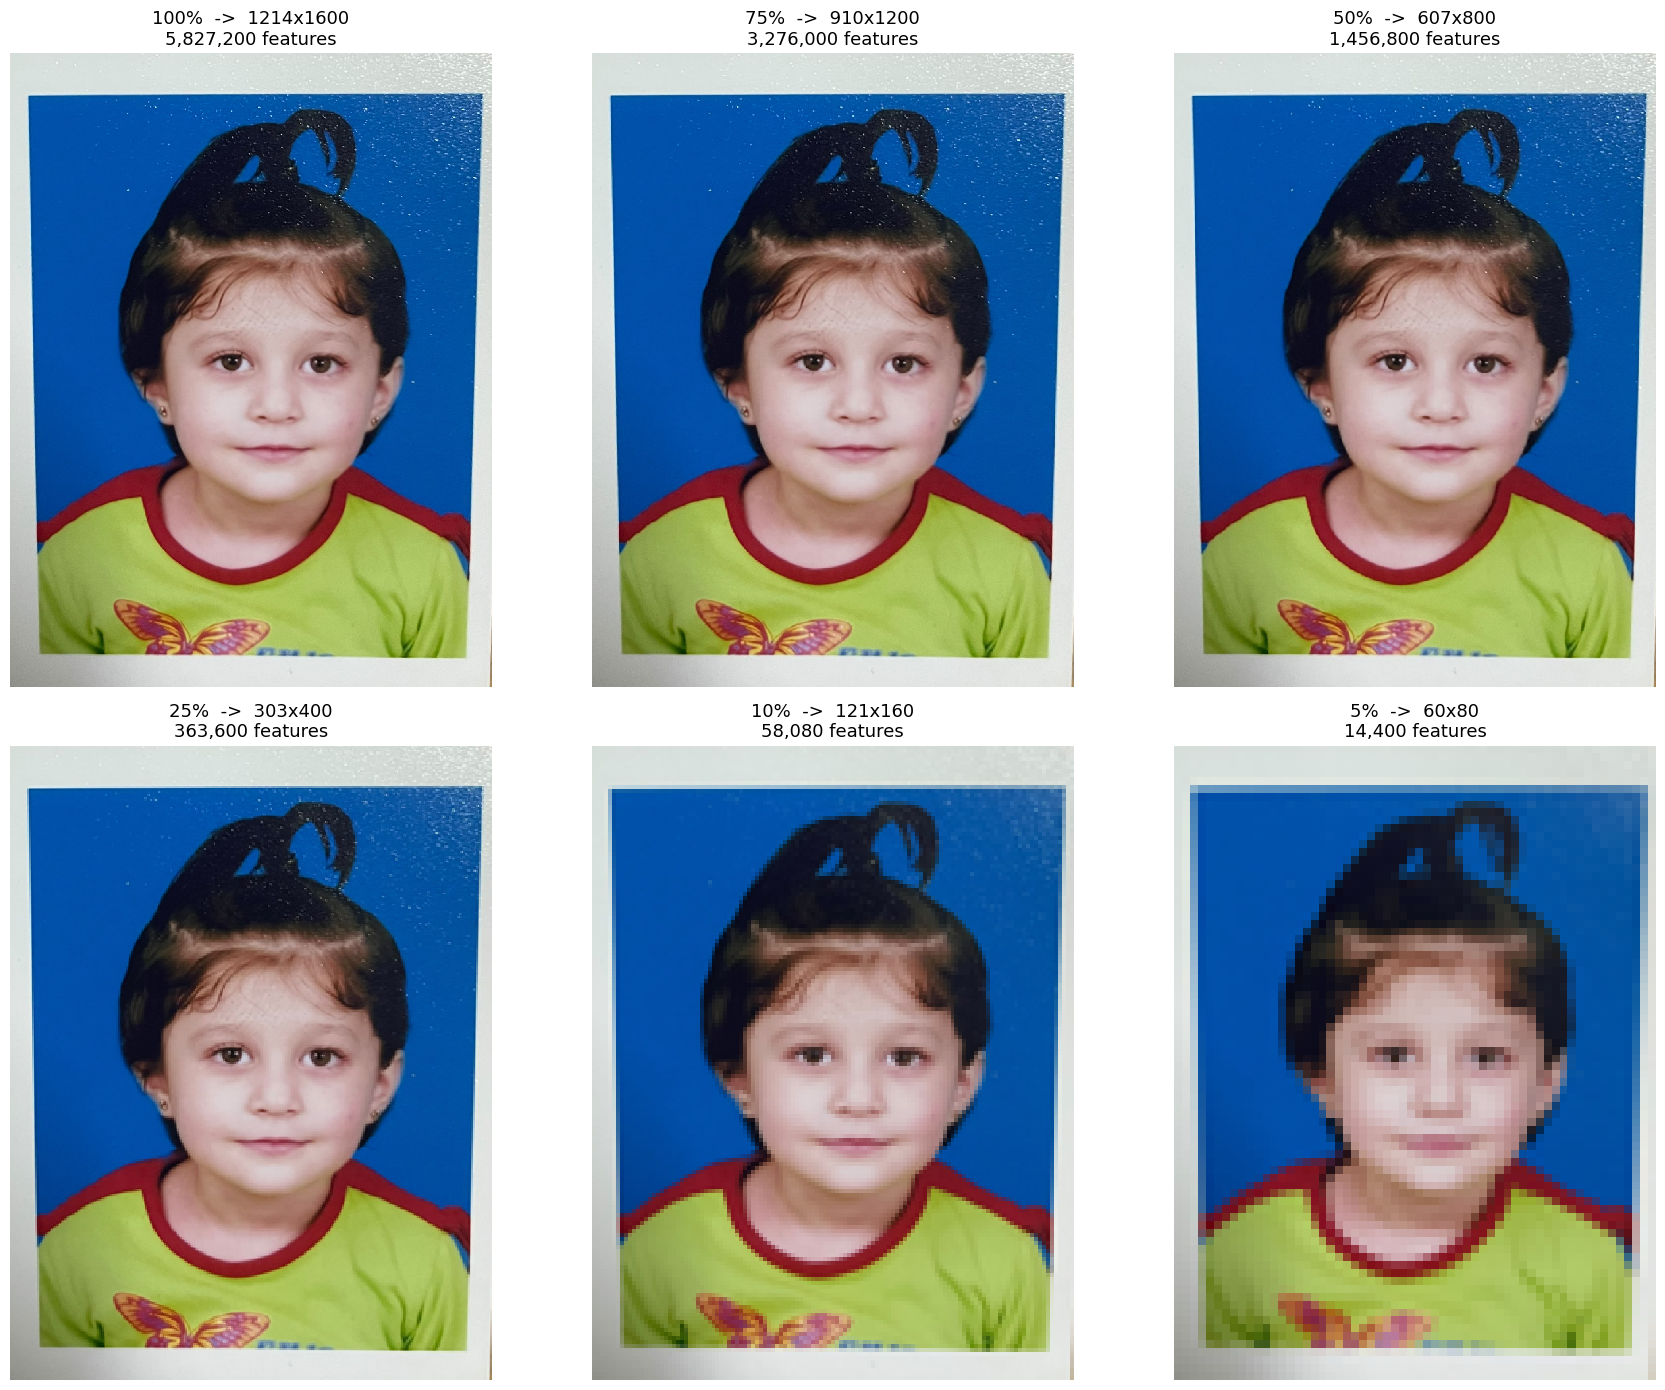

In [21]:
percentages = [100, 75, 50, 25, 10, 5]

fig, axes = plt.subplots(2, 3, figsize=(18, 14), dpi=100)
for ax, p in zip(axes.flatten(), percentages):
    new_w, new_h = max(1, int(w * p / 100)), max(1, int(h * p / 100))
    small = original_image.resize((new_w, new_h))
    # scale back up to original size WITHOUT smoothing, so lost pixels show as blocks
    shown = small.resize((w, h), Image.NEAREST)
    ax.imshow(shown, interpolation='nearest')
    ax.set_title(f"{p}%  ->  {new_w}x{new_h}\n{new_w*new_h*3:,} features", fontsize=13)
    ax.axis('off')

plt.tight_layout()
plt.show()

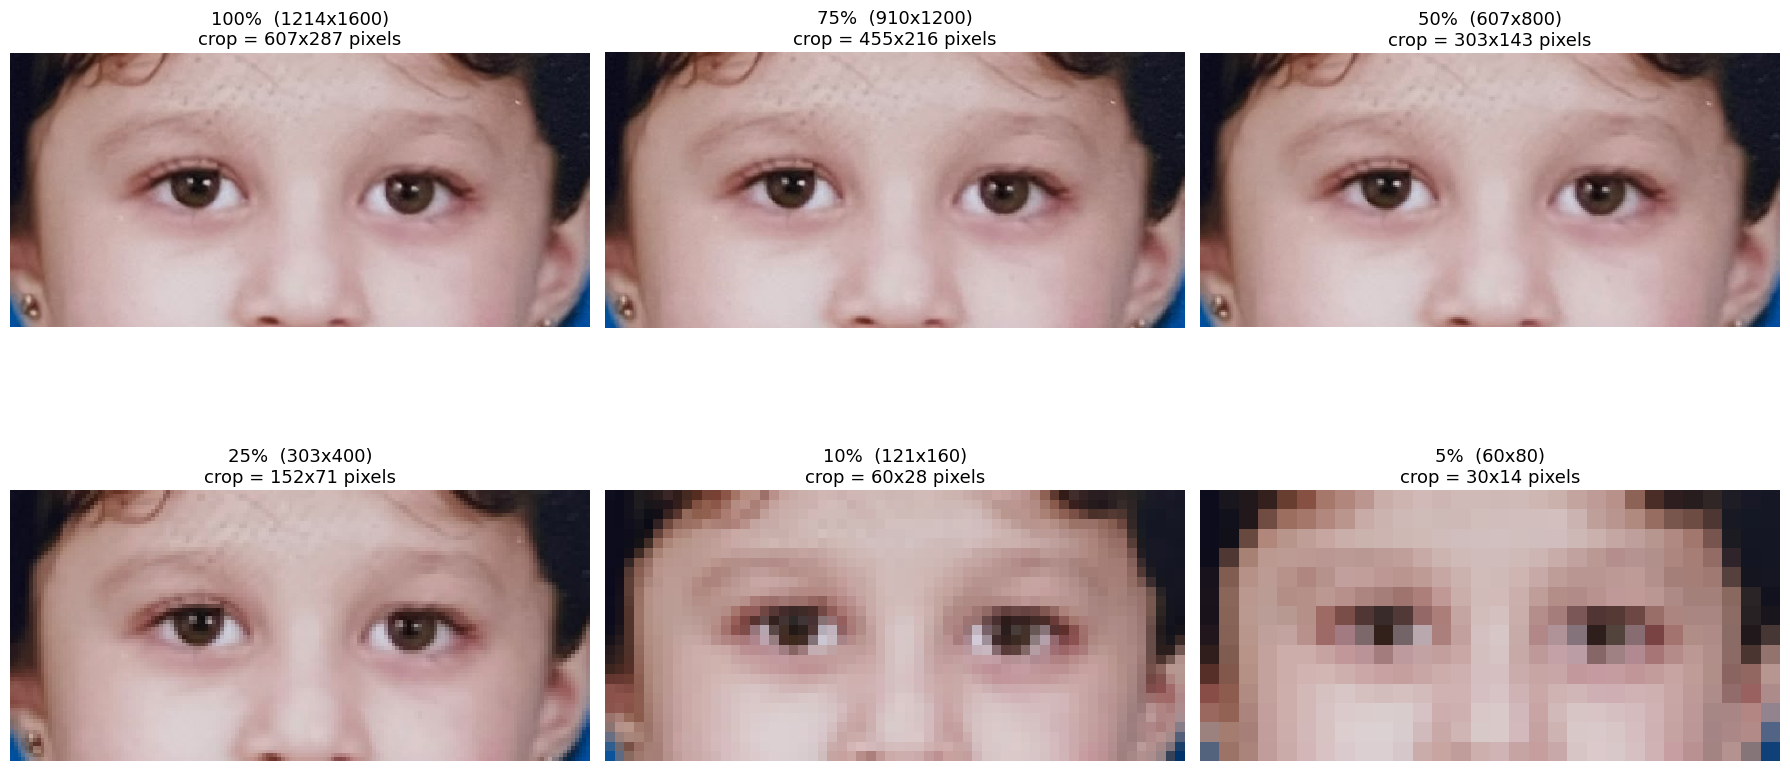

In [22]:
percentages = [100, 75, 50, 25, 10, 5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
for ax, p in zip(axes.flatten(), percentages):
    new_w, new_h = max(1, int(w * p / 100)), max(1, int(h * p / 100))
    small = original_image.resize((new_w, new_h))
    # same relative region from every size (adjust these fractions to move the crop)
    box = (int(0.30 * new_w), int(0.40 * new_h), int(0.80 * new_w), int(0.58 * new_h))
    crop = small.crop(box)
    ax.imshow(crop, interpolation='nearest')
    ax.set_title(f"{p}%  ({new_w}x{new_h})\ncrop = {crop.size[0]}x{crop.size[1]} pixels", fontsize=13)
    ax.axis('off')

plt.tight_layout()
plt.show()